# 11. A joint halo emulator, and the simulations it needs

This notebook follows Secs. 4.5 and 4.6 of Paper I.
Notebook 10 found that the halo layer limits the cosmology: the bias must be known to 0.2–0.5 per cent for the hosts of galaxies, the abundance to 0.2–3 per cent and the concentration to 1–4 per cent.
The goal is a joint emulator of the three, measured on N-body simulations.
Here we estimate the statistical error a suite of simulations reaches on each ingredient, per 0.5 dex of mass, and compare two designs with the tolerance; the design tables come from the tutorial data bundle.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

import json

import matplotlib
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from ggah_mod import DIFFERENTIABLE
from ggah_mod.cosmology import PLANCK18, ln10A_s_for_sigma8, make_pk
from ggah_mod.halos.field import make_field
import ggah_mod.halos as H

load = lambda name: json.load(open(T.data_path(name)))

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = False


## The errors of one box

In a periodic box of side $L$, a 0.5-dex window of mass with abundance $\bar n$ and bias $b$ gives (Eq. 50)

$$\frac{\sigma_b}{b} = \Big[b^2\bar n\sum_{k\le0.1\,h\,{\rm Mpc}^{-1}}N_kP(k)\Big]^{-1/2},\qquad
\frac{\sigma_n}{n} = (\bar nL^3)^{-1/2},\qquad
\sigma_{\langle\ln c\rangle} = \frac{\sigma_{\ln c}}{(\bar nL^3)^{1/2}},$$

with $N_k$ the wavevectors from $2\pi/L$ to $0.1\,h\,{\rm Mpc}^{-1}$ and $\sigma_{\ln c} = 0.31$–0.43 the scatter of the concentration.
The error on $b$ assumes Gaussian modes, a linear bias and a halo–matter cross-spectrum free of shot noise.
The counts are Poisson because the boxes start from fixed amplitudes, which fix their mean density.
The paper tested these formulas on 16 boxes of $250\,h^{-1}{\rm Mpc}$.

We evaluate them at the cosmology of the Uchuu simulation (*Planck* 2015, no massive neutrinos) at $z = 0.248$, with `tinker08` and `tinker10` at $200{\rm m}$.

In [2]:
pk = make_pk("emu_pk")
c = PLANCK18.replace(Omega_m=0.3089, Omega_b=0.0486, h=0.6774, n_s=0.9667, sum_mnu=0.0)
c = c.replace(ln10A_s=ln10A_s_for_sigma8(0.8159, c, pk))
Z = 1.0 / 0.80122 - 1.0
HALF, KMAX = 0.25, 0.1
M0 = np.round(np.arange(9.75, 15.76, 0.05), 2)            # window centres, log10 M200m
Q = ("b", "dn/dM", "c")

mg = np.linspace(9.4, 16.1, 700)
fld = make_field(c, DIFFERENTIABLE, pk, z=Z, m=10.0**mg, mdef="200m", hmf_model="tinker08", bias_model="tinker10")
dndlnm = np.asarray(fld.m * fld.dndm)
bias = np.asarray(fld.bias)
kl = np.logspace(-4, 0, 400)
pl = np.asarray(pk.pk(kl, Z, c))


def window(m0):
    """(n, b): abundance [(h^-1 Mpc)^-3] and count-weighted bias of the 0.5-dex window centred on m0."""
    lm = np.linspace(m0 - HALF, m0 + HALF, 51)
    dn = np.interp(lm, mg, dndlnm)
    n = np.trapezoid(dn, np.log(10.0) * lm)
    return n, np.trapezoid(dn * np.interp(lm, mg, bias), np.log(10.0) * lm) / n


win = {m: window(m) for m in M0}
print(f"z = {Z:.3f}; n(>10^12) window: {win[12.0][0]:.2e} (Mpc/h)^-3, b = {win[12.0][1]:.2f}")

z = 0.248; n(>10^12) window: 4.99e-03 (Mpc/h)^-3, b = 0.88


A window enters a box only above $n_p m_p$ at its lower edge, with $n_p$ particles per halo: 500 for the abundance, 200 or 500 for the bias, 2000 for the concentration in a reference box, and 20 in a ratio box.

In [3]:
budget = load("suite/33_error_budget.json")["per_mass"]
slnc_m = np.array([float(k) for k in budget])
slnc_v = np.array([v["sigma_lnc"] for v in budget.values()])


def box_errors(L, mp, nps):
    V = L**3
    k = np.geomspace(2 * np.pi / L, KMAX, 300)
    sp = np.trapezoid(V / (2 * np.pi**2) * k**2 * np.interp(k, kl, pl), k)     # sum_k N_k P(k)
    out = {q: np.full(M0.size, np.nan) for q in Q}
    for i, m in enumerate(M0):
        n, b = win[m]
        lo = 10 ** (m - HALF)
        if lo >= nps["b"] * mp:
            out["b"][i] = np.sqrt(1 / (n * sp)) / b
        if lo >= nps["dn/dM"] * mp:
            out["dn/dM"][i] = 1 / np.sqrt(n * V)
        if lo >= nps["c"] * mp:
            out["c"][i] = np.interp(m, slnc_m, slnc_v) / np.sqrt(n * V)
    return out


def combine(errs):
    """Inverse-variance combination of the boxes that resolve each window."""
    res = {}
    for q in Q:
        w = np.nansum(np.array([e[q] for e in errs]) ** -2.0, axis=0)
        res[q] = np.where(w > 0, 1 / np.sqrt(np.where(w > 0, w, 1.0)), np.nan)
    return res

## Two suite designs

The level at *Planck* comes from reference boxes; the dependence on cosmology from ratios to *Planck*, in boxes that share its phases.
A ratio between two runs with the same phases keeps a fraction $s$ of the noise of two independent boxes ($s = 0.35$, the largest measured).
The error of one cosmology is the reference and the ratio added in quadrature.
The planned suite and the amended suite of Sec. 4.6 differ in their boxes and in the particles per halo required for the bias.

In [4]:
suite = load("suite/65_suite_tables.json")
red = load("suite/72_suite_redesign.json")
S = red["s_design"]


def suite_errors(ref, ratio, np_b):
    r = combine([box_errors(L, mp, {"b": np_b, "dn/dM": 500, "c": 2000}) for L, mp in ref])
    t = combine([box_errors(L, mp, {"b": 20, "dn/dM": 20, "c": 2000}) for L, mp in ratio])
    t = {q: np.sqrt(2) * S * v for q, v in t.items()}
    return {q: np.sqrt(r[q] ** 2 + t[q] ** 2) for q in Q}


geo = suite["geometries"]
planned = suite_errors([(g["box"], g["m_p"]) for g in geo if g["set"] == "absolute"],
                       [(g["box"], g["m_p"]) for g in geo if g["set"] == "ratio"], 500)
ad = red["designs"][red["adopted"]]
amended = suite_errors([(b["side_Mpc_h"], b["m_p_Msun_h"]) for b in ad["ref_boxes"]],
                       [(b["side_Mpc_h"], b["m_p_Msun_h"]) for b in ad["ratio_boxes"]], 200)
print(f"amended suite: {len(ad['ref_boxes'])} reference boxes of "
      f"{min(b['side_Mpc_h'] for b in ad['ref_boxes']):.0f}-{max(b['side_Mpc_h'] for b in ad['ref_boxes']):.0f} Mpc/h, "
      f"{ad['total_core_hours'] / 1e6:.1f} million core-hours")

#: Tolerance (lo, hi) in per cent, and the mass range it applies to, from notebook 10 and the paper
TOL = {"b": [((10.5, 13.0), (0.193, 0.451), "galaxy hosts")],
       "dn/dM": [((10.5, 12.5), (0.157, 0.662), "galaxy hosts"), ((13.5, 15.0), (0.615, 2.83), "clusters")],
       "c": [((12.0, 15.0), (0.983, 4.23), "")]}
worst = {}
for name, tot in (("planned", planned), ("amended", amended)):
    for q, rows in TOL.items():
        for rng, tl, lab in rows:
            sel = (M0 >= rng[0]) & (M0 <= rng[1])
            worst[name, q, lab] = float(np.nanmax(100 * tot[q][sel]))
            print(f"{name:8s} {q:6s} {lab:13s} worst {worst[name, q, lab]:.2f}%, tolerance {tl[0]:.2g}-{tl[1]:.2g}%"
                  + ("  meets it" if worst[name, q, lab] <= tl[0] else ""))

amended suite: 8 reference boxes of 252-4917 Mpc/h, 45.6 million core-hours
planned  b      galaxy hosts  worst 0.52%, tolerance 0.19-0.45%
planned  dn/dM  galaxy hosts  worst 0.13%, tolerance 0.16-0.66%  meets it
planned  dn/dM  clusters      worst 2.79%, tolerance 0.61-2.8%
planned  c                    worst 1.04%, tolerance 0.98-4.2%
amended  b      galaxy hosts  worst 0.17%, tolerance 0.19-0.45%  meets it
amended  dn/dM  galaxy hosts  worst 0.11%, tolerance 0.16-0.66%  meets it
amended  dn/dM  clusters      worst 0.53%, tolerance 0.61-2.8%  meets it
amended  c                    worst 0.60%, tolerance 0.98-4.2%  meets it


## The MultiDark measurements

The green points of the figure are the errors per bin of the MultiDark measurements of Comparat et al. (2017) at $z = 0$, read off their figures, and mapped to mass with $\sigma(M)$ at *Planck* 2015, $M_{\rm vir}$ taken as $M_{200{\rm m}}$.
That $\sigma(M)$ is the one of `colossus` (Eisenstein & Hu transfer function), as in the script that made the figure of the paper; with this package's at the same cosmology the points move by a few hundredths of a dex.

In [5]:
from colossus.cosmology import cosmology as cc15
from colossus.lss import peaks

c15 = cc15.setCosmology("planck15")
mg15 = np.linspace(9.0, 16.0, 400)
xs = np.log10(1 / c15.sigma(peaks.lagrangianR(10.0**mg15), 0.0))
d = load("suite/74_comparat17_errors.json")
md17 = {}
for q, key in (("b", "bias"), ("dn/dM", "fsigma")):
    v = np.array([p for p in d[key] if p[1] > 0])
    xc, ec = [], []
    for lo in np.arange(-0.45, 0.35, 0.05):
        sel = (v[:, 0] >= lo) & (v[:, 0] < lo + 0.05)
        if sel.sum() >= 2:
            xc.append(lo + 0.025)
            ec.append(100 * np.median(v[sel, 1]))
    md17[q] = (np.interp(xc, xs, mg15), np.array(ec))

## The figure

Fig. 14 of the paper.
The hatched bands are the errors that shift $S_8$ by less than $0.3\sigma$; the blue lines the goal of the emulator, half their lower edge.

planned  b      recomputed here / published: within 0.0%
planned  dn/dM  recomputed here / published: within 0.0%
planned  c      recomputed here / published: within 0.0%
amended  b      recomputed here / published: within 0.0%
amended  dn/dM  recomputed here / published: within 0.0%
amended  c      recomputed here / published: within 0.0%


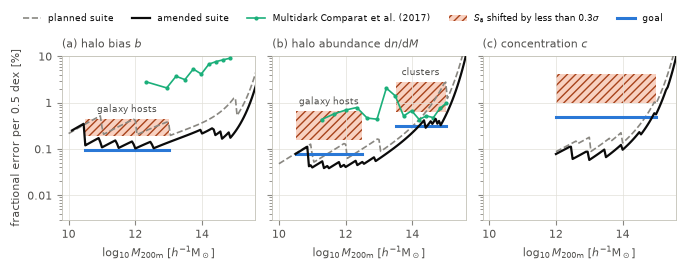

In [6]:
# The published curves, drawn in the style of the proposal the figure was made for.
pub = load("suite/70_suite_errors.json")
assert pub["log10M"] == M0.tolist()
for name, tot in (("planned", planned), ("amended", amended)):
    for q in Q:
        ok = np.isfinite(tot[q])
        dev = np.nanmax(np.abs(100 * tot[q][ok] / np.asarray(pub[f"{name}_total_percent"][q])[ok] - 1))
        print(f"{name:8s} {q:6s} recomputed here / published: within {dev:.1f}%")
INK, SEC, MUT = "#0b0b0b", "#52514e", "#898781"
GRID, BASE = "#e1e0d9", "#c3c2b7"
blue, green = "#2a78d6", "#1baf7a"
STYLE = {"font.size": 8, "font.family": "sans-serif", "text.color": INK, "axes.labelcolor": SEC,
         "axes.titlecolor": INK, "axes.edgecolor": BASE, "axes.linewidth": 0.6, "axes.grid": True,
         "grid.color": GRID, "grid.linewidth": 0.5, "xtick.color": MUT, "ytick.color": MUT,
         "xtick.labelcolor": SEC, "ytick.labelcolor": SEC, "xtick.direction": "out", "ytick.direction": "out",
         "legend.frameon": False, "legend.fontsize": 6.5, "figure.facecolor": "white",
         "savefig.facecolor": "white", "savefig.bbox": "tight", "lines.linewidth": 1.4}
plt.rcdefaults()
plt.rcParams.update(STYLE)
fig, axes = plt.subplots(1, 3, figsize=(6.9, 2.45), sharey=True)
titles = {"b": "(a) halo bias $b$", "dn/dM": r"(b) halo abundance $\mathrm{d}n/\mathrm{d}M$", "c": "(c) concentration $c$"}
hatch = dict(facecolor=(0.92, 0.41, 0.20, 0.30), edgecolor="#a8431c", hatch="////", lw=0)
for ax, q in zip(axes, Q):
    for r, t, lab in TOL[q]:
        ax.fill_between(r, t[0], t[1], zorder=1, **hatch)
        ax.plot(r, [t[0] / 2] * 2, color=blue, lw=2.2, zorder=4)
        if lab:
            ax.text(np.mean(r), t[1] * 1.25, lab, ha="center", va="bottom", fontsize=6.5, color=SEC)
    ax.plot(M0, pub["planned_total_percent"][q], color=MUT, lw=1.2, ls="--", zorder=3)
    ax.plot(M0, pub["amended_total_percent"][q], color=INK, lw=1.6, zorder=5)
    if q in md17:
        ax.plot(*md17[q], color=green, lw=1.2, marker="o", ms=2, zorder=4)
    ax.set_yscale("log")
    ax.set_xlim(9.8, 15.6)
    ax.set_ylim(3e-3, 10)
    ax.set_xlabel(r"$\log_{10} M_{200\mathrm{m}}$ [$h^{-1}\mathrm{M}_\odot$]")
    ax.set_title(titles[q], fontsize=8, color=SEC, loc="left")
axes[0].set_ylabel("fractional error per 0.5 dex [%]")
axes[0].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
fig.legend([Line2D([], [], color=MUT, lw=1.2, ls="--"), Line2D([], [], color=INK, lw=1.6),
            Line2D([], [], color=green, lw=1.2, marker="o", ms=2), Patch(**hatch), Line2D([], [], color=blue, lw=2.2)],
           ["planned suite", "amended suite", "Multidark Comparat et al. (2017)",
            r"$S_8$ shifted by less than $0.3\sigma$", "goal"],
           loc="upper center", bbox_to_anchor=(0.5, 1.09), ncol=5, fontsize=6.5)
fig.tight_layout()
T.save_figure(fig, "fig_suite_errors", dpi=200)
T.paper_style()

The amended suite meets the tolerance on every ingredient; the planned one misses it on the bias, the abundance of clusters and the concentration.
Resolution systematics are not included in these errors.

## Exercises

1. Use the halo–halo spectrum, $P_{hh}/P_{\rm lin}$, instead of the cross-spectrum with the matter to measure $b$: the shot noise of the haloes enters. How much larger must the boxes be?
2. Remove the ratio boxes and measure every cosmology with its own reference boxes ($s = 1/\sqrt2$). How does the cost change for 100 cosmologies?
3. Halve the tolerance (a threshold of $|\beta| = 0.15$). Which ingredient becomes the hardest to reach?

This is the last notebook of the main text. Appendices A and B follow.